# Aufgabe 1 – Air Quality Sensor Calibration
**Data Science WS 2026/27 | HdM**



In [1]:
from pathlib import Path
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
try:
    import missingno as msno
except ModuleNotFoundError:
    msno = None  # Alternative Darstellung ohne zusätzliche Installation
from sklearn import linear_model
from sklearn.metrics import mean_absolute_error
from sklearn.model_selection import train_test_split

# Projektordner finden – funktioniert vom Projekt- und Notebook-Verzeichnis aus.
projektordner = Path.cwd().resolve()
while not (projektordner / "src" / "Data" / "pm25_train.csv").is_file():
    if projektordner == projektordner.parent:
        raise FileNotFoundError("Bitte das Notebook innerhalb des Projektordners starten.")
    projektordner = projektordner.parent
datenordner = projektordner / "src" / "Data"

df = pd.read_csv(datenordner / "pm25_train.csv")
print("Zeilen, Spalten:", df.shape)
print(df.dtypes)
display(df.head())

Zeilen, Spalten: (3613, 17)
timestamp                str
year_month               str
pm25_target          float64
pm25_lowcost         float64
no                   float64
no2                  float64
o3                   float64
co2                  float64
black_carbon         float64
ufp                  float64
temperature          float64
relative_humidity    float64
pressure             float64
wind_speed           float64
wind_direction       float64
rain_vol             float64
glob_rad             float64
dtype: object


,timestamp,year_month,pm25_target,pm25_lowcost,no,no2,o3,co2,black_carbon,ufp,temperature,relative_humidity,pressure,wind_speed,wind_direction,rain_vol,glob_rad
0,2024-06-03 11:00:00,2024-06,6.26,4.48,1.1,5.9,42.6,452.8,0.393,4757.4,14.951,61.676,1013.662,0.765,66.126,45.35,436.257
1,2024-06-03 12:00:00,2024-06,5.99,4.10,1.2,5.7,44.3,451.0,0.377,5033.6,15.224,60.849,1013.400,1.329,51.441,45.35,480.905
2,2024-06-03 13:00:00,2024-06,6.01,3.69,1.6,5.9,43.7,450.4,0.364,5846.9,15.782,59.932,1013.103,1.331,52.637,45.35,708.009
3,2024-06-03 14:00:00,2024-06,7.93,4.53,1.4,6.7,43.3,454.4,0.453,5975.0,15.877,59.112,1012.868,1.380,54.700,45.35,547.942
4,2024-06-03 15:00:00,2024-06,7.49,3.82,1.3,6.3,42.2,453.5,0.399,5211.7,16.108,58.005,1012.576,1.775,50.297,45.35,550.972


## 1a – Deskriptive Statistik

In [2]:
display(df.describe().T)
print("Fehlende Werte pro Spalte:")
display(df.isna().sum().to_frame("Fehlende Werte"))
print("Duplikate:", df.duplicated().sum())
print("Mittelwert PM2.5 Referenz:",df["pm25_target"].mean())
print("Median PM2.5 Referenz:",df["pm25_target"].median())

,count,mean,std,min,25%,50%,75%,max
pm25_target,3409.0,3.342502,2.235040,0.240,1.7300,2.710,4.4700,15.560
pm25_lowcost,3152.0,5.517113,22.606241,0.300,1.7000,2.740,4.8125,595.530
no,3591.0,6.813729,37.340151,-2.700,0.4000,1.600,4.5500,1131.700
no2,3591.0,7.889167,6.335310,0.300,3.4000,6.700,10.7000,94.800
o3,2866.0,26.270761,13.788739,0.400,15.4000,25.200,35.7000,78.600
co2,2686.0,460.002494,21.934798,427.500,443.1000,455.100,473.1750,701.200
black_carbon,3611.0,0.875096,1.206205,0.045,0.3505,0.627,1.0360,36.684
ufp,2836.0,9496.228914,4891.164131,2077.700,6319.2500,8820.400,11652.1750,110138.800
temperature,3185.0,17.774074,5.062794,5.752,14.2130,17.391,21.2350,33.166
relative_humidity,3185.0,73.822057,14.103189,35.542,64.4400,76.890,85.3360,96.298


Fehlende Werte pro Spalte:


,Fehlende Werte
timestamp,0
year_month,0
pm25_target,204
pm25_lowcost,461
no,22
no2,22
o3,747
co2,927
black_carbon,2
ufp,777


Duplikate: 0
Mittelwert PM2.5 Referenz: 3.3425022000586684
Median PM2.5 Referenz: 2.71


In [3]:
display(pd.DataFrame({"fehlend":df.isna().sum(),"fehlend_%":(df.isna().mean()*100).round(2),"eindeutige_Werte":df.nunique()}))
print("Monate:")
display(df["year_month"].value_counts().sort_index())

,fehlend,fehlend_%,eindeutige_Werte
timestamp,0,0.00,3613
year_month,0,0.00,5
pm25_target,204,5.65,806
pm25_lowcost,461,12.76,950
no,22,0.61,380
no2,22,0.61,277
o3,747,20.68,585
co2,927,25.66,752
black_carbon,2,0.06,1578
ufp,777,21.51,2811


Monate:


year_month
2024-06    661
2024-07    744
2024-08    744
2024-09    720
2024-10    744
Name: count, dtype: int64


ANALYSE FEHLENDER WERTE


co2                  927
ufp                  777
o3                   747
pm25_lowcost         461
rain_vol             428
pressure             428
relative_humidity    428
temperature          428
wind_speed           428
glob_rad             428
wind_direction       428
pm25_target          204
no                    22
no2                   22
black_carbon           2
timestamp              0
year_month             0
dtype: int64

Gesamtanzahl fehlender Werte: 6158


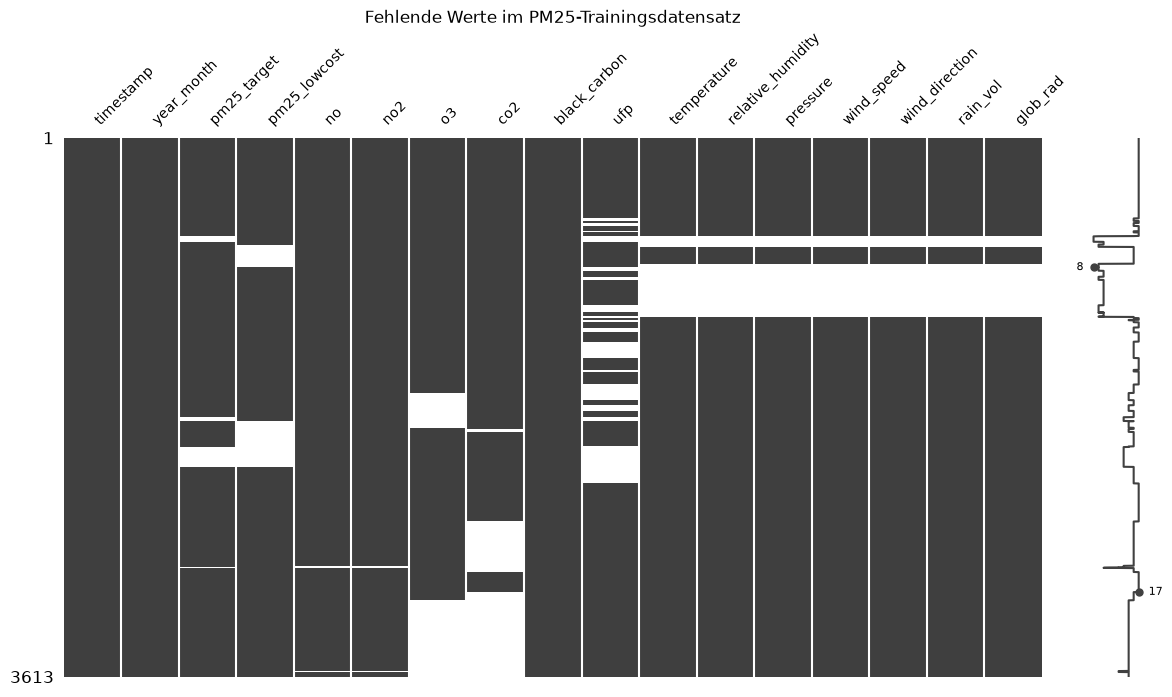

In [4]:
# Analyse der fehlenden Werte
print("\n" + "=" * 80)
print("ANALYSE FEHLENDER WERTE")
print("=" * 80)

# Fehlende Werte pro Spalte zählen und absteigend sortieren
display(df.isnull().sum().sort_values(ascending=False))

# Gesamtanzahl der fehlenden Werte berechnen
print("Gesamtanzahl fehlender Werte:", df.isnull().sum().sum())

# Visuelle Darstellung der fehlenden Werte
if msno is not None:
    msno.matrix(df, figsize=(14, 7), fontsize=10)
else:
    # Alternative ohne missingno: Weiß = fehlend, Schwarz = vorhanden
    plt.figure(figsize=(14, 7))
    plt.imshow(df.isnull(), aspect="auto", cmap="gray", interpolation="nearest")
    plt.xticks(range(len(df.columns)), df.columns, rotation=65, ha="right")
    plt.ylabel("Messungen")

plt.title("Fehlende Werte im PM25-Trainingsdatensatz")
plt.show()

### Verteilungen, Boxplots und Zusammenhänge

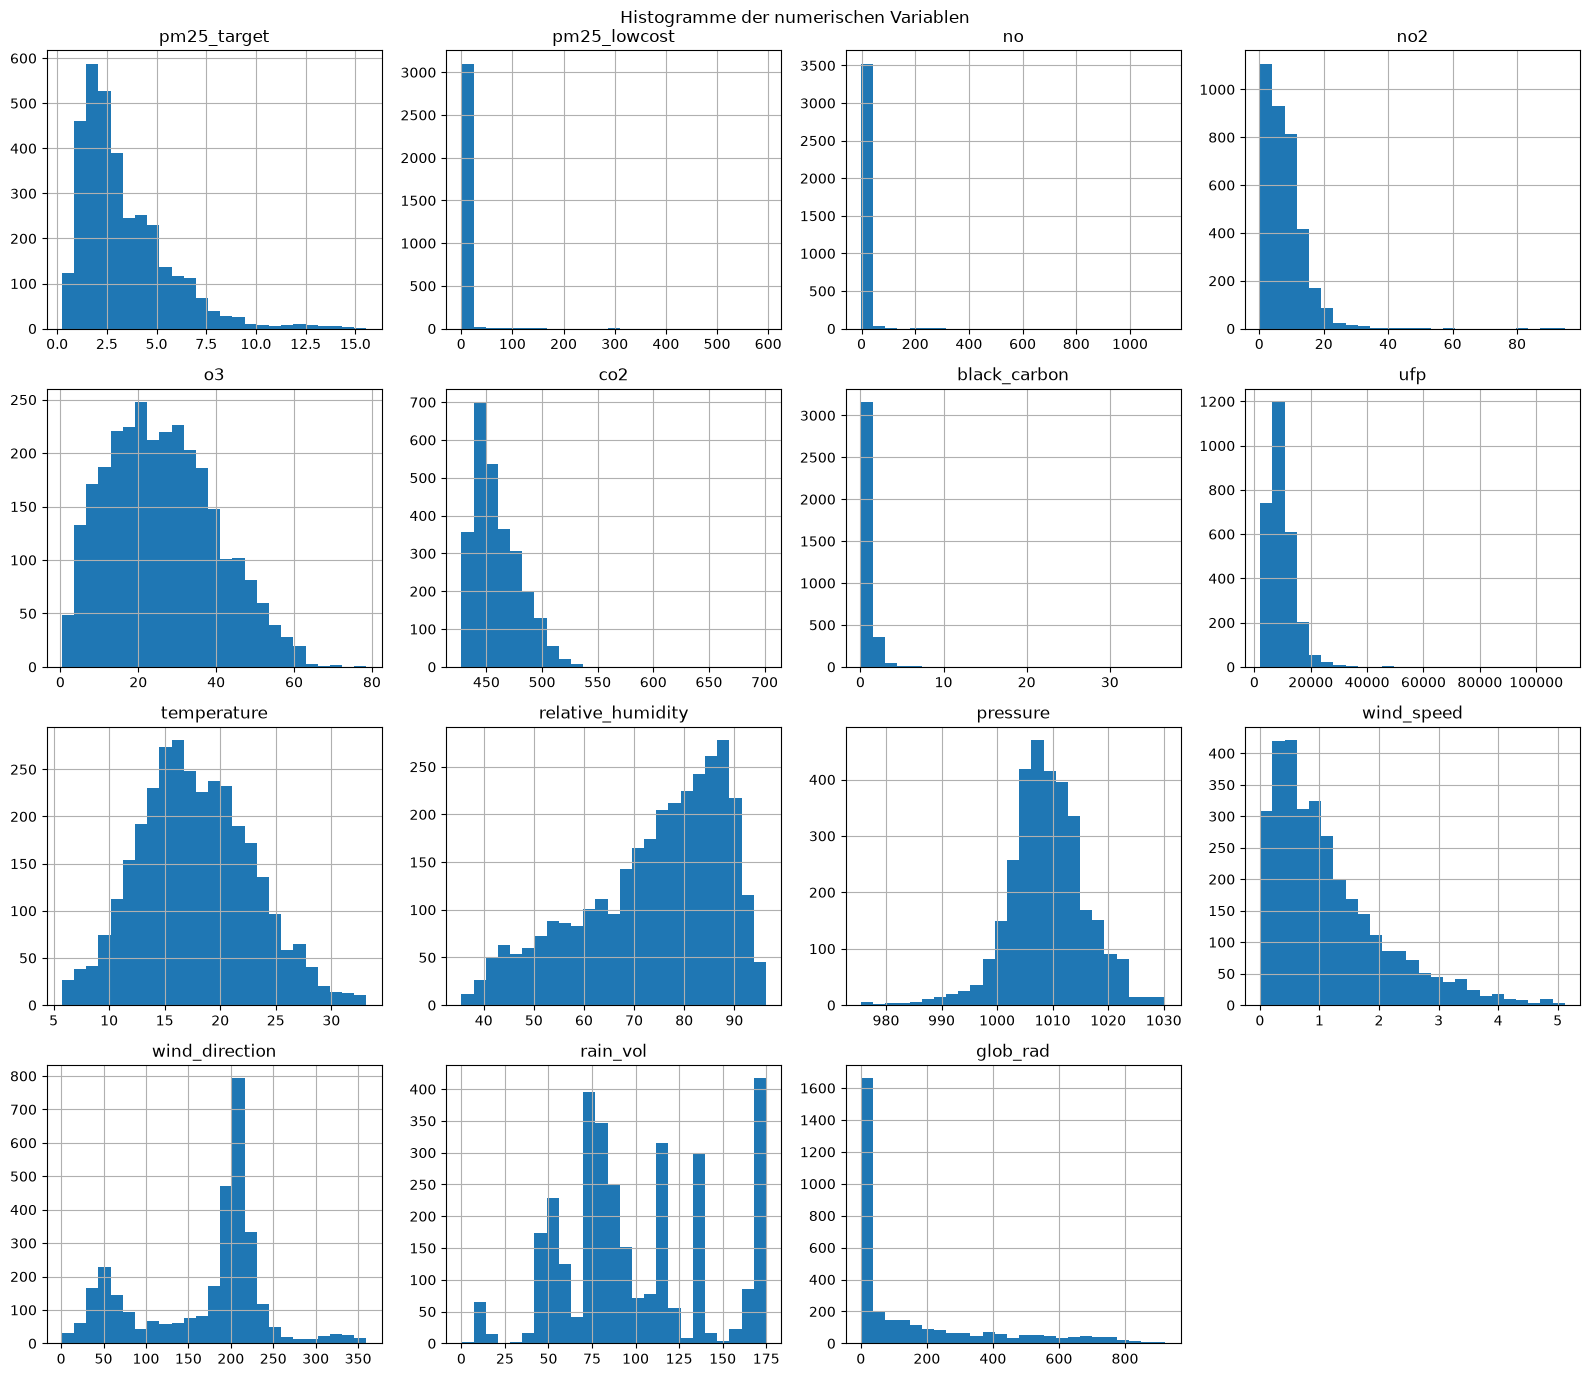

In [5]:
df.select_dtypes(include="number").hist(bins=25, figsize=(16,14))
plt.suptitle("Histogramme der numerischen Variablen")
plt.tight_layout()
plt.show()

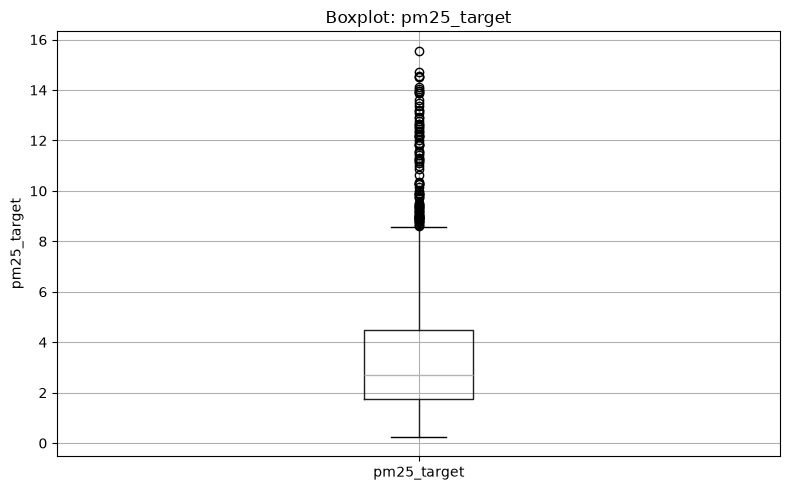

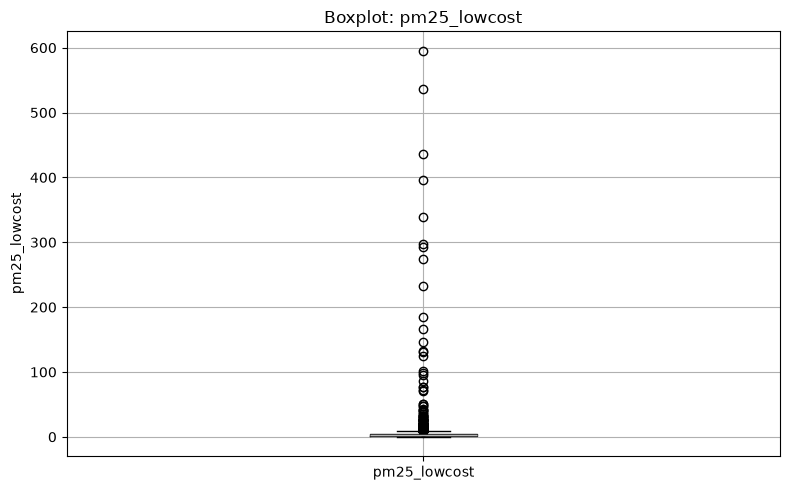

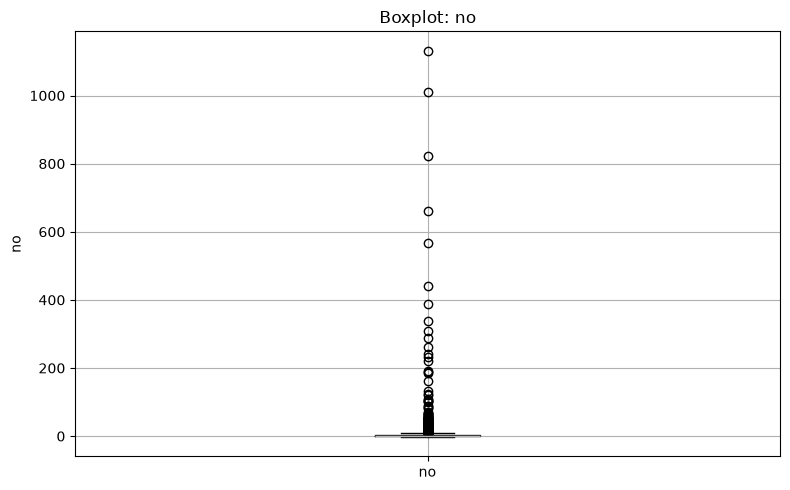

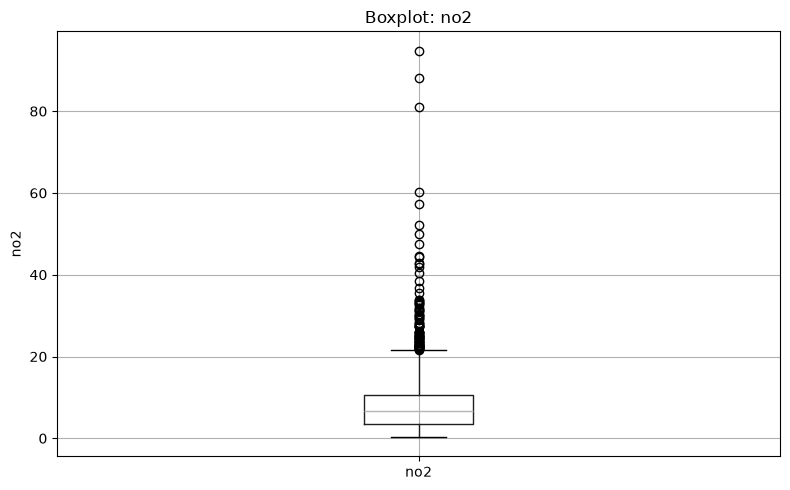

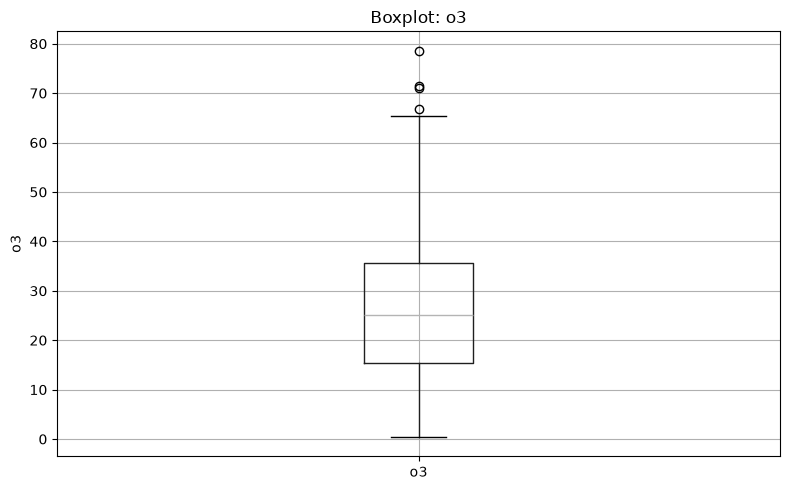

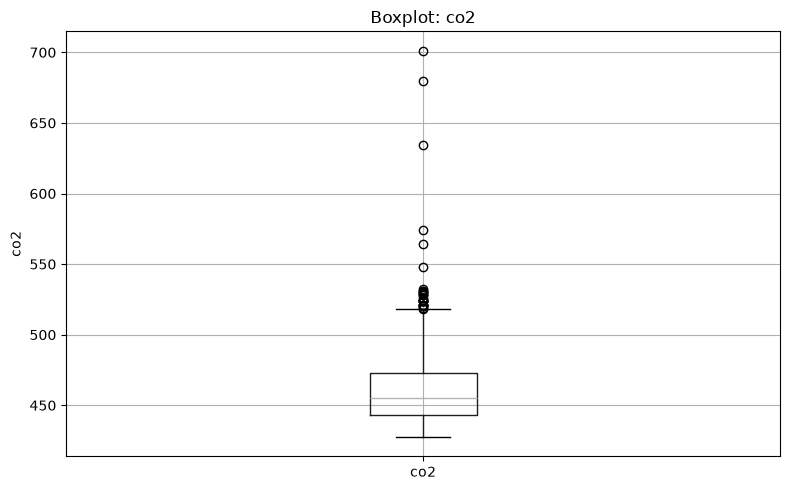

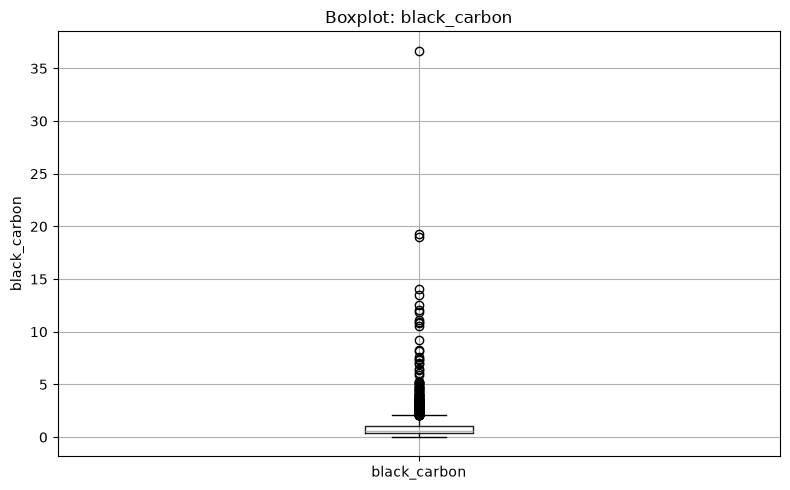

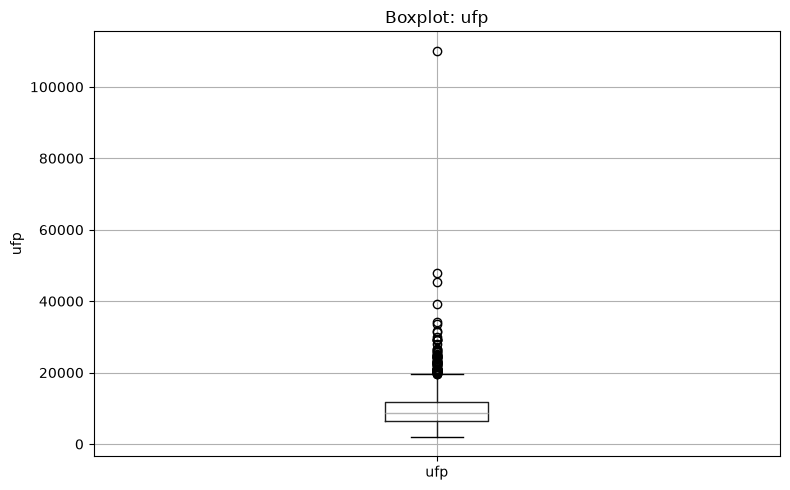

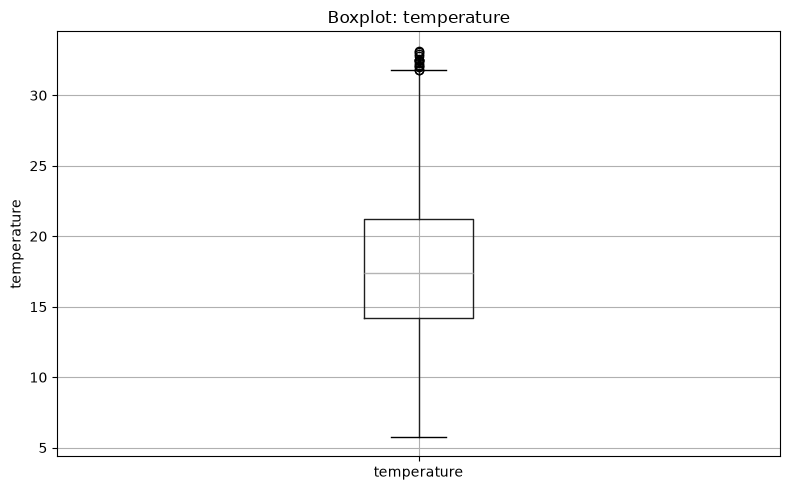

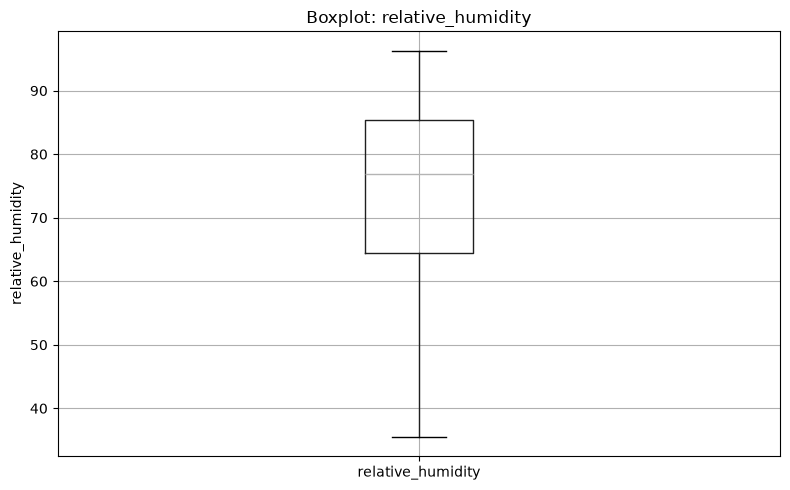

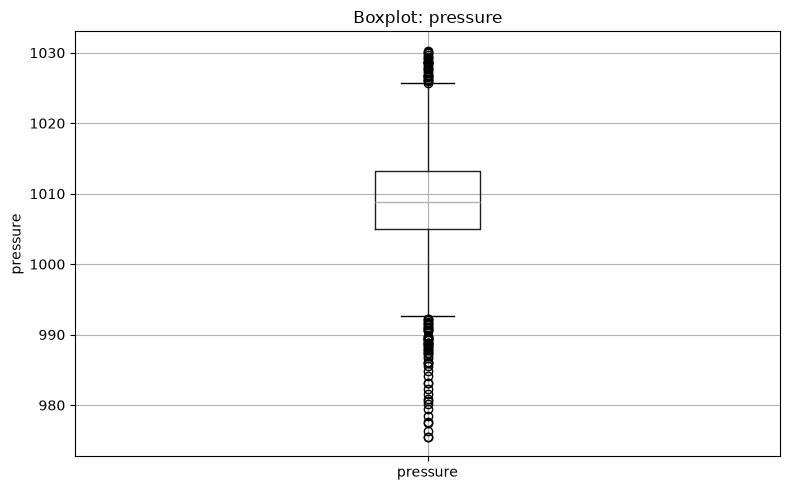

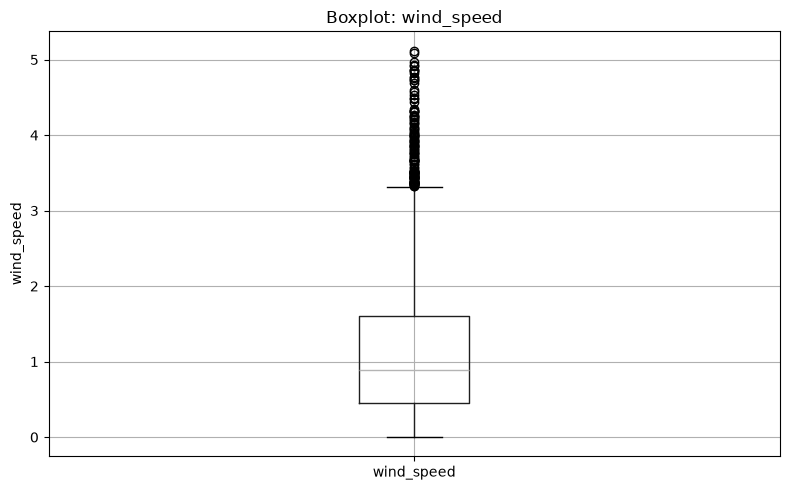

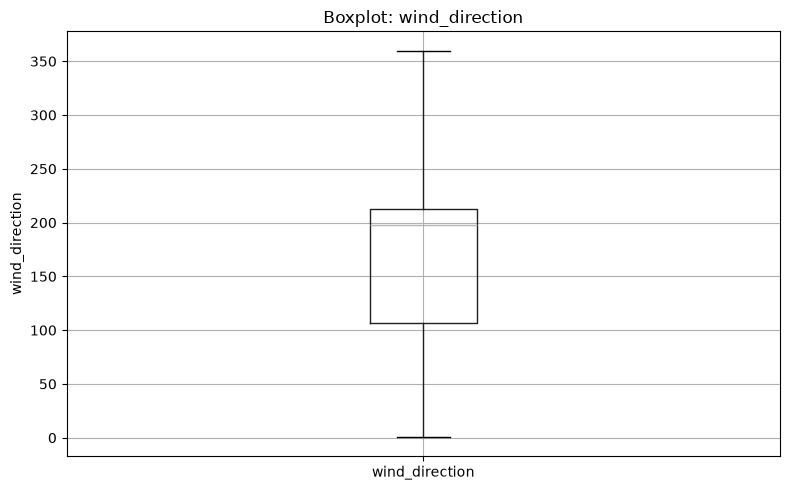

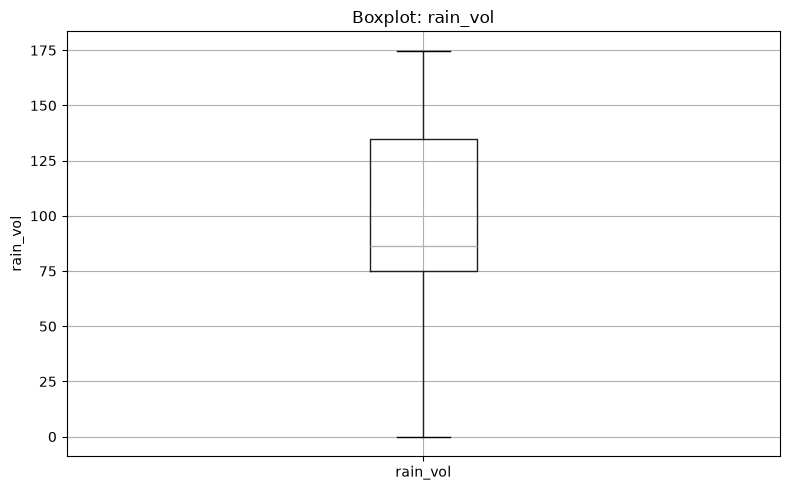

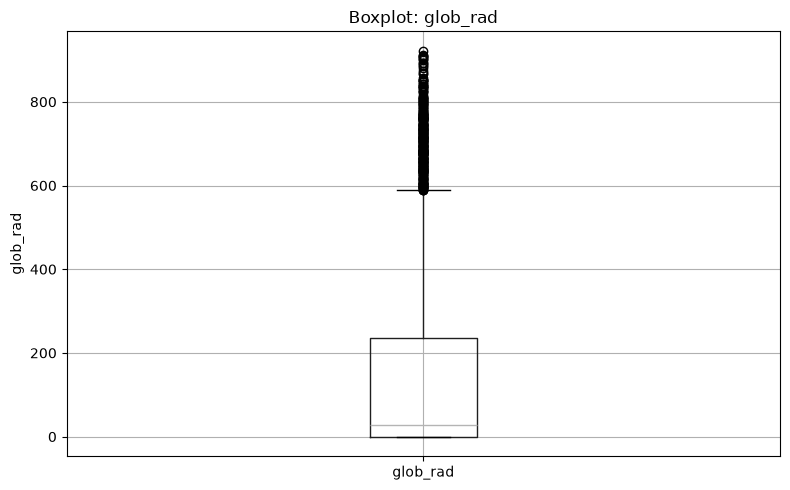

In [6]:
cols = df.select_dtypes(include="number").columns.tolist()

# Für jedes Feature ein Boxplot
for col in cols:
    df.boxplot(column=col, figsize=(8, 5), rot=0)

    plt.title("Boxplot: " + col)
    plt.ylabel(col)
    plt.tight_layout()
    plt.show()

,pm25_target,pm25_lowcost,no,no2,o3,co2,black_carbon,ufp,temperature,relative_humidity,pressure,wind_speed,wind_direction,rain_vol,glob_rad
pm25_target,1.000000,0.079080,0.062023,0.251434,0.001535,0.246649,0.304341,0.259145,0.131985,0.117563,0.241631,-0.187832,-0.168721,-0.004144,0.035941
pm25_lowcost,0.079080,1.000000,0.005144,0.045588,-0.153761,0.129620,0.028256,-0.044596,-0.207869,0.179469,0.174059,0.025729,0.034973,0.117282,-0.096712
no,0.062023,0.005144,1.000000,0.578172,-0.090074,0.410201,0.708824,0.471290,-0.083879,0.122381,0.087449,-0.093178,-0.012317,0.244804,-0.015383
no2,0.251434,0.045588,0.578172,1.000000,-0.476387,0.655728,0.668831,0.580505,-0.107864,0.343428,0.149851,-0.329415,0.061033,0.151998,-0.276250
o3,0.001535,-0.153761,-0.090074,-0.476387,1.000000,-0.685182,-0.171845,-0.161044,0.614385,-0.811682,-0.082717,0.236809,-0.265262,-0.196179,0.501727
co2,0.246649,0.129620,0.410201,0.655728,-0.685182,1.000000,0.445863,0.260585,-0.313842,0.656304,0.081908,-0.245005,0.210526,0.066661,-0.402348
black_carbon,0.304341,0.028256,0.708824,0.668831,-0.171845,0.445863,1.000000,0.628952,-0.001692,0.167695,0.107389,-0.171813,0.013128,0.203867,-0.067543
ufp,0.259145,-0.044596,0.471290,0.580505,-0.161044,0.260585,0.628952,1.000000,0.186068,-0.019234,0.131297,-0.280591,-0.065482,-0.085474,0.046785
temperature,0.131985,-0.207869,-0.083879,-0.107864,0.614385,-0.313842,-0.001692,0.186068,1.000000,-0.612303,-0.218823,0.107562,-0.149702,-0.515393,0.431617
relative_humidity,0.117563,0.179469,0.122381,0.343428,-0.811682,0.656304,0.167695,-0.019234,-0.612303,1.000000,0.046743,-0.233914,0.239731,0.320063,-0.588084


Korrelationen mit Referenz-PM2.5:


pm25_target          1.000000
black_carbon         0.304341
ufp                  0.259145
no2                  0.251434
co2                  0.246649
pressure             0.241631
temperature          0.131985
relative_humidity    0.117563
pm25_lowcost         0.079080
no                   0.062023
glob_rad             0.035941
o3                   0.001535
rain_vol            -0.004144
wind_direction      -0.168721
wind_speed          -0.187832
Name: pm25_target, dtype: float64

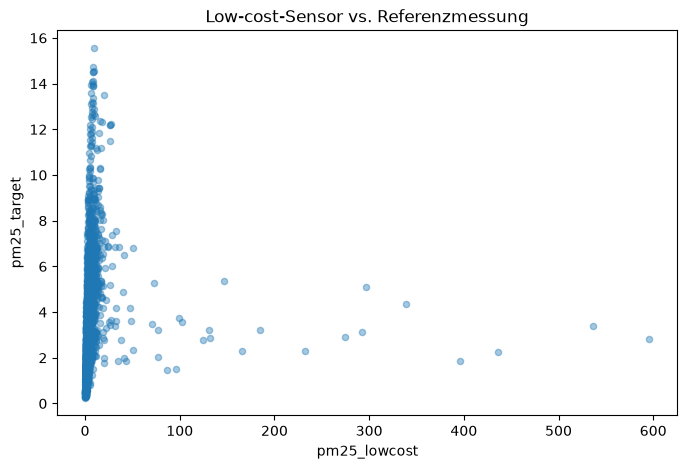

In [7]:
corr = df.select_dtypes(include="number").corr()
display(corr.style.background_gradient(cmap="coolwarm"))
print("Korrelationen mit Referenz-PM2.5:")
display(corr["pm25_target"].sort_values(ascending=False))
df.plot.scatter(x="pm25_lowcost",y="pm25_target",figsize=(8,5),alpha=0.4)
plt.title("Low-cost-Sensor vs. Referenzmessung")
plt.show()

In [8]:
# Korrelationsmatrix für alle numerischen Spalten berechnen
corr = df.select_dtypes(include="number").corr()

# Absolute Korrelation aller Features mit der Zielvariable pm25_target bestimmen
# Durch abs() werden auch negative Korrelationen berücksichtigt
relevanz = corr["pm25_target"].abs()

# Nur Features auswählen, deren absolute Korrelation mindestens 0.15 beträgt
relevante_features = relevanz[relevanz >= 0.15].index.tolist()

# pm25_lowcost zusätzlich aufnehmen, da es für die Baseline benötigt wird
if "pm25_lowcost" not in relevante_features:
    relevante_features.append("pm25_lowcost")

# Zielvariable an die erste Stelle setzen
# Restliche Features nach ihrer absoluten Korrelation absteigend sortieren
relevante_features = ["pm25_target"] + [
    feature for feature in relevanz.sort_values(ascending=False).index
    if feature in relevante_features and feature != "pm25_target"
]

# Neue Korrelationsmatrix nur mit den ausgewählten Features erstellen
corr_relevant = df[relevante_features].corr()

# Heatmap als farbige Tabelle anzeigen
# Rot = positive Korrelation, Blau = negative Korrelation
display(corr_relevant.style.background_gradient(cmap="coolwarm"))

,pm25_target,black_carbon,ufp,no2,co2,pressure,wind_speed,wind_direction,pm25_lowcost
pm25_target,1.000000,0.304341,0.259145,0.251434,0.246649,0.241631,-0.187832,-0.168721,0.079080
black_carbon,0.304341,1.000000,0.628952,0.668831,0.445863,0.107389,-0.171813,0.013128,0.028256
ufp,0.259145,0.628952,1.000000,0.580505,0.260585,0.131297,-0.280591,-0.065482,-0.044596
no2,0.251434,0.668831,0.580505,1.000000,0.655728,0.149851,-0.329415,0.061033,0.045588
co2,0.246649,0.445863,0.260585,0.655728,1.000000,0.081908,-0.245005,0.210526,0.129620
pressure,0.241631,0.107389,0.131297,0.149851,0.081908,1.000000,-0.291062,-0.183658,0.174059
wind_speed,-0.187832,-0.171813,-0.280591,-0.329415,-0.245005,-0.291062,1.000000,0.141304,0.025729
wind_direction,-0.168721,0.013128,-0.065482,0.061033,0.210526,-0.183658,0.141304,1.000000,0.034973
pm25_lowcost,0.079080,0.028256,-0.044596,0.045588,0.129620,0.174059,0.025729,0.034973,1.000000


In [9]:
num = df.select_dtypes(include="number")
q1 = num.quantile(0.25)
q3 = num.quantile(0.75)
iqr = q3-q1
outliers = ((num.lt(q1-1.5*iqr)) | (num.gt(q3+1.5*iqr))).sum()
display(pd.DataFrame({"Minimum":num.min(),"Maximum":num.max(),"IQR-Ausreißer":outliers,"Anteil_%":(outliers/len(df)*100).round(2)}).sort_values("IQR-Ausreißer",ascending=False))

,Minimum,Maximum,IQR-Ausreißer,Anteil_%
no,-2.700,1131.700,433,11.98
glob_rad,0.000,922.239,259,7.17
pm25_lowcost,0.300,595.530,238,6.59
black_carbon,0.045,36.684,211,5.84
wind_speed,0.006,5.119,122,3.38
pm25_target,0.240,15.560,98,2.71
no2,0.300,94.800,87,2.41
pressure,975.468,1030.293,85,2.35
ufp,2077.700,110138.800,77,2.13
co2,427.500,701.200,28,0.77


### Interpretation für Aufgabe 2
?

## 1b – Untersuchung der Feature Importance (lineare Regression)

**Ziel:** Die Kalibrierung der PM2.5-Messung wird zunächst ausschließlich mit `pm25_lowcost` (Baseline) und anschließend mit schrittweise ergänzten Merkmalen getestet. Für alle Varianten wird **LinearRegression** eingesetzt. Die Auswahl erfolgt anhand des **Validierungs-MAE** (kleiner ist besser); ergänzend wird **R²** berichtet (größer ist besser).

**Vorgehensweise:** Train/Validierung werden einmalig getrennt. Bei der Forward Selection wird in jedem Schritt das Feature ergänzt, das den MAE auf der *gleichen Validierungsmenge* am stärksten reduziert. Die Mediane zum Auffüllen fehlender Feature-Werte werden ausschließlich im jeweiligen Training ermittelt und auf die Validierung übertragen. Keine Validierungszeile wird wegen fehlender Features gelöscht, und Zielwerte werden nicht verändert.

**Einschränkung:** Weil viele Feature-Kombinationen auf derselben Validierungsmenge verglichen werden, kann auch die Merkmalsauswahl auf diese Menge überangepasst werden. Der offizielle Testsatz bleibt deshalb bis zur endgültigen Auswahl unangetastet.

In [10]:
# Nur Trainingszeilen mit einem bekannten Referenzwert verwenden
labeled = df.dropna(subset=["pm25_target"]).copy()
print("Ohne Referenzlabel:", len(df) - len(labeled))

# 80 % Modelltraining, 20 % Validierung – kein zusätzlicher Holdout
# Der offizielle Testdatensatz pm25_test.csv wird erst nach der Modellauswahl genutzt.
train, valid = train_test_split(labeled, test_size=0.20, random_state=42)
print("Train:", len(train), "Validierung:", len(valid))

Ohne Referenzlabel: 204
Train: 2727 Validierung: 682


**Umgang mit fehlenden Zielwerten:** Für das überwachte Training benötigen wir einen bekannten `pm25_target`-Wert. Daher werden nur im ursprünglichen **Trainingsdatensatz** Zeilen ohne Label für das Modelltraining ausgeschlossen. `df` selbst wird nicht verändert. Die gelabelten Trainingsdaten werden wie im Kursbeispiel mit `train_test_split(test_size=0.2, random_state=42)` aufgeteilt: **80 % Training und 20 % Validierung**. 



In [11]:
features = ["pm25_lowcost"] + [c for c in df.select_dtypes(include="number").columns if c not in ["pm25_target","pm25_lowcost"]]

def prepare(train_part, eval_part, selected):
    median = train_part[selected].median()
    return train_part[selected].fillna(median),eval_part[selected].fillna(median)

def evaluate(selected, train_part=train, eval_part=valid):
    X_train,X_eval=prepare(train_part,eval_part,selected)
    reg=linear_model.LinearRegression()
    reg.fit(X_train,train_part["pm25_target"])
    pred=reg.predict(X_eval)
    return reg,mean_absolute_error(eval_part["pm25_target"],pred),reg.score(X_eval,eval_part["pm25_target"])

results=[]
selected=["pm25_lowcost"]
reg,mae,r2=evaluate(selected)
results.append({"Schritt":0,"Neues Feature":"Baseline","Features":selected.copy(),"MAE":mae,"R2":r2})
remaining=features[1:]
# Greedy Forward Selection: jeweils das auf der Validierung beste weitere Feature hinzufügen
for step in range(1,len(features)):
    options=[]
    for f in remaining:
        model,m,r=evaluate(selected+[f])
        options.append((m,f,r))
    best_mae,best_feature,best_r2=min(options)
    selected.append(best_feature)
    remaining.remove(best_feature)
    results.append({"Schritt":step,"Neues Feature":best_feature,"Features":selected.copy(),"MAE":best_mae,"R2":best_r2})
results_df=pd.DataFrame(results)
base_mae=results_df.loc[0,"MAE"]
base_r2=results_df.loc[0,"R2"]
results_df["MAE Verbesserung absolut"]=base_mae-results_df["MAE"]
results_df["MAE Verbesserung %"]=(base_mae-results_df["MAE"])/base_mae*100
results_df["R2 Verbesserung absolut"]=results_df["R2"]-base_r2
display(results_df.drop(columns="Features").round(4))

,Schritt,Neues Feature,MAE,R2,MAE Verbesserung absolut,MAE Verbesserung %,R2 Verbesserung absolut
0,0,Baseline,1.7480,0.0058,0.0000,0.0000,0.0000
1,1,black_carbon,1.6038,0.1561,0.1442,8.2485,0.1503
2,2,no,1.5358,0.2103,0.2121,12.1352,0.2046
3,3,temperature,1.4903,0.2453,0.2576,14.7385,0.2396
4,4,relative_humidity,1.4282,0.2669,0.3197,18.2919,0.2612
5,5,pressure,1.3774,0.3207,0.3706,21.2024,0.3149
6,6,wind_direction,1.3650,0.3460,0.3830,21.9118,0.3402
7,7,co2,1.3450,0.3490,0.4030,23.0541,0.3432
8,8,o3,1.3334,0.3678,0.4145,23.7144,0.3620
9,9,rain_vol,1.3326,0.3669,0.4153,23.7618,0.3611


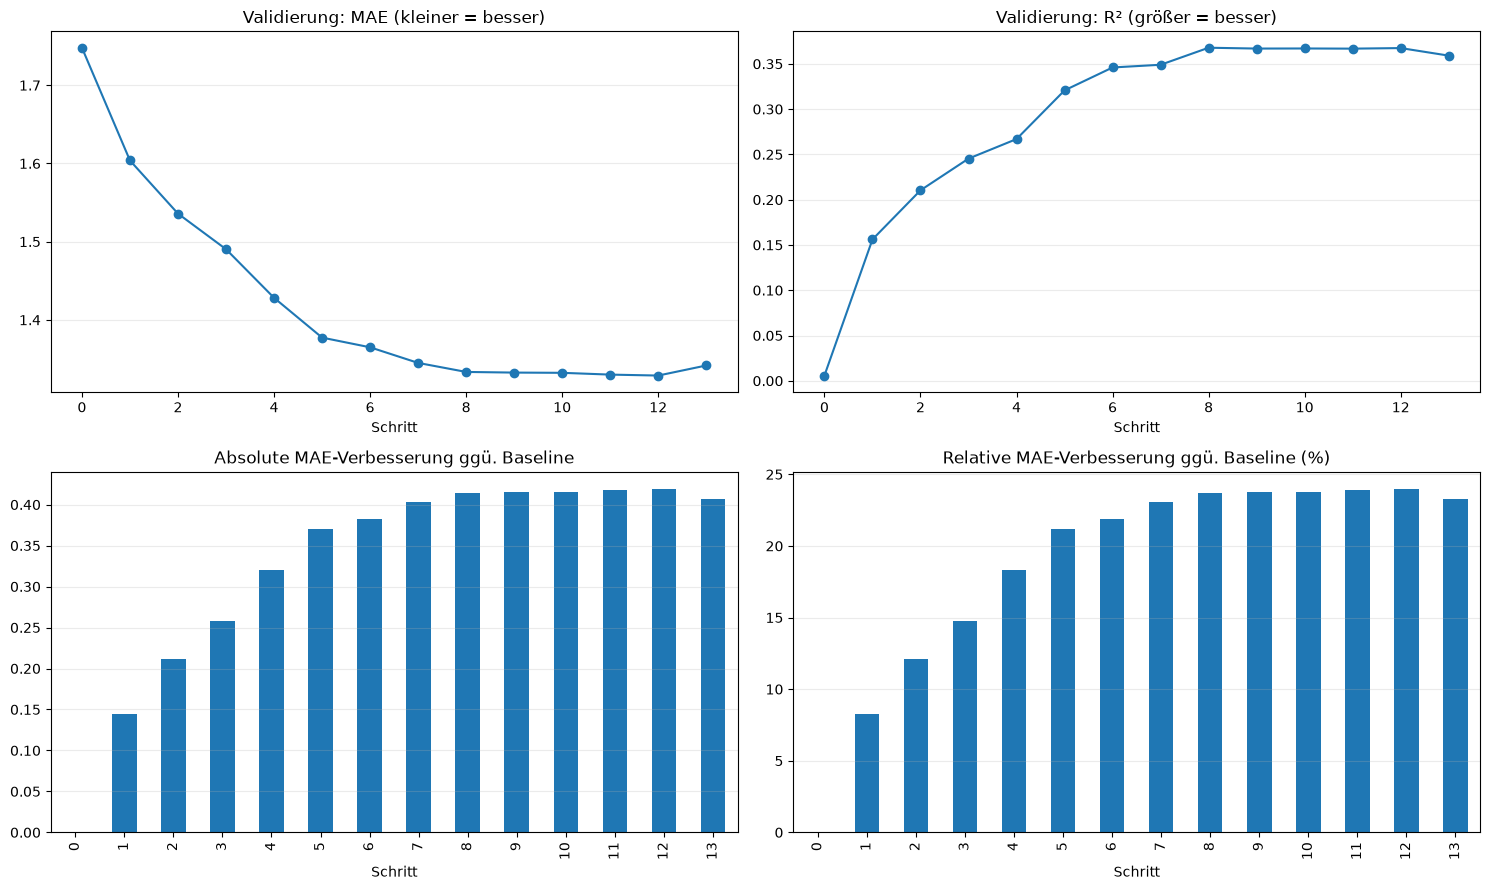

R²-Verbesserung zur Baseline (absolute Differenz und relativ zur |Baseline|):


,Schritt,Neues Feature,R2 Verbesserung absolut,R2 Verbesserung % (Basis-R2)
0,0,Baseline,0.000,0.000
1,1,black_carbon,0.150,2601.483
2,2,no,0.205,3540.353
3,3,temperature,0.240,4145.933
4,4,relative_humidity,0.261,4519.852
5,5,pressure,0.315,5450.302
6,6,wind_direction,0.340,5888.104
7,7,co2,0.343,5939.688
8,8,o3,0.362,6265.318
9,9,rain_vol,0.361,6249.304


,Schritt,Neues Feature,MAE,R2,MAE-Änderung zum vorherigen Schritt,R²-Änderung zum vorherigen Schritt
0,0,Baseline,1.7480,0.0058,NaN,NaN
1,1,black_carbon,1.6038,0.1561,-0.1442,0.1503
2,2,no,1.5358,0.2103,-0.0679,0.0542
3,3,temperature,1.4903,0.2453,-0.0455,0.0350
4,4,relative_humidity,1.4282,0.2669,-0.0621,0.0216
5,5,pressure,1.3774,0.3207,-0.0509,0.0538
6,6,wind_direction,1.3650,0.3460,-0.0124,0.0253
7,7,co2,1.3450,0.3490,-0.0200,0.0030
8,8,o3,1.3334,0.3678,-0.0115,0.0188
9,9,rain_vol,1.3326,0.3669,-0.0008,-0.0009


Interpretation: Ein positiver MAE-Unterschied gegenüber dem vorigen Schritt bedeutet eine Verschlechterung.


In [12]:
# Verlauf der Modellgüte und absolute/relative Änderungen gegenüber der Baseline
results_df["R2 Verbesserung % (Basis-R2)"] = np.where(
    abs(base_r2) > 1e-12, (results_df["R2"] - base_r2) / abs(base_r2) * 100, np.nan
)
fig, axes = plt.subplots(2, 2, figsize=(15, 9))
results_df.plot(x="Schritt", y="MAE", marker="o", ax=axes[0, 0], legend=False,
                title="Validierung: MAE (kleiner = besser)")
results_df.plot(x="Schritt", y="R2", marker="o", ax=axes[0, 1], legend=False,
                title="Validierung: R² (größer = besser)")
results_df.plot(x="Schritt", y="MAE Verbesserung absolut", kind="bar", ax=axes[1, 0],
                legend=False, title="Absolute MAE-Verbesserung ggü. Baseline")
results_df.plot(x="Schritt", y="MAE Verbesserung %", kind="bar", ax=axes[1, 1],
                legend=False, title="Relative MAE-Verbesserung ggü. Baseline (%)")
for ax in axes.flat:
    ax.grid(axis="y", alpha=0.25)
plt.tight_layout()
plt.show()

# Beide R²-Vergleiche dokumentieren: Differenz und relative Veränderung.
# Die relative R²-Änderung kann bei einer Basis nahe 0 irreführend groß sein.
print("R²-Verbesserung zur Baseline (absolute Differenz und relativ zur |Baseline|):")
display(results_df[["Schritt", "Neues Feature", "R2 Verbesserung absolut",
                    "R2 Verbesserung % (Basis-R2)"]].round(3))

# Marginaler Einfluss des neu hinzugefügten Merkmals in genau dieser Auswahlreihenfolge
marginal = results_df[["Schritt", "Neues Feature", "MAE", "R2"]].copy()
marginal["MAE-Änderung zum vorherigen Schritt"] = marginal["MAE"].diff()
marginal["R²-Änderung zum vorherigen Schritt"] = marginal["R2"].diff()
display(marginal.round(4))
print("Interpretation: Ein positiver MAE-Unterschied gegenüber dem vorigen Schritt bedeutet eine Verschlechterung.")

### Auswahl des besten Modells und einmaliger Test auf offiziellen Daten

Die Feature-Kombination mit dem **kleinsten Validierungs-MAE** wird ausgewählt. Danach wird die lineare Regression mit allen Trainingszeilen mit vorhandenem Zielwert erneut trainiert. Erst jetzt erfolgt die Auswertung auf `pm25_test.csv`. Zum fairen Vergleich wird eine Baseline auf **genau denselben testseitig auswertbaren Zeilen** bewertet.

Es werden **keine Testzeilen gelöscht und keine Test-Labels verändert**. Fehlende Feature-Werte ersetzt das Modell mit Trainingsmedianen; **jede** Testzeile erhält eine Vorhersage. MAE und R² können nur dort berechnet werden, wo `pm25_target` vorhanden ist. Die Zahl der nicht bewertbaren Testzeilen wird ausgewiesen; die Prognosedatei enthält weiterhin alle Testzeilen.

Beste Feature-Kombination: ['pm25_lowcost', 'black_carbon', 'no', 'temperature', 'relative_humidity', 'pressure', 'wind_direction', 'co2', 'o3', 'rain_vol', 'wind_speed', 'glob_rad', 'ufp']
Validierung MAE: 1.3288 R²: 0.3674
Testzeilen insgesamt: 1464
Testzeilen mit vorhandenem Label: 1419
Testzeilen ohne Label: 45
Offizieller Test – Baseline MAE / R²: 2.1627 -0.0046
Offizieller Test – Bestes Modell MAE / R²: 2.2634 -0.2087
MAE Verbesserung absolut: -0.1007
MAE Verbesserung relativ (%): -4.66
Testprognosen gespeichert: pm25_test_predictions.csv


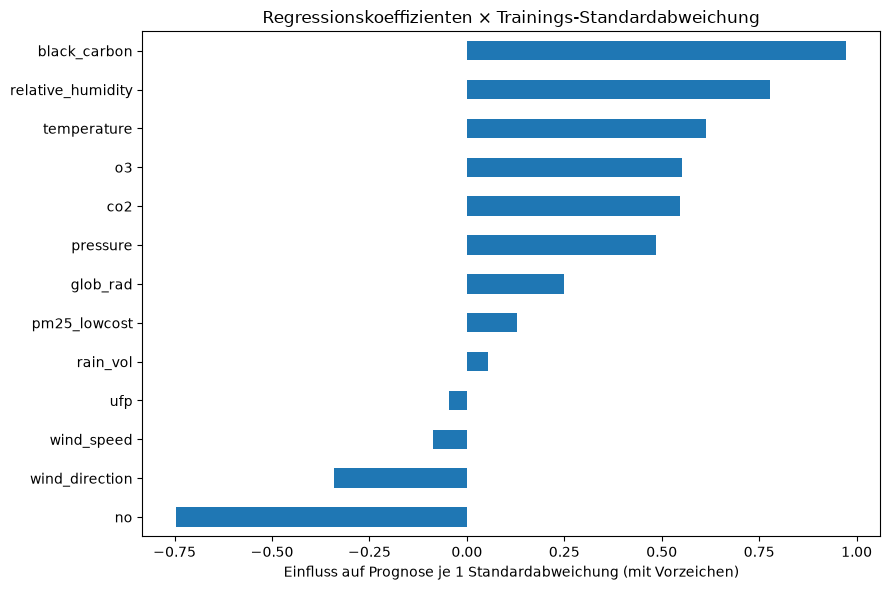

Achtung: Korrelationen zwischen Features können Koeffizienten verzerren.


,Datensatz,MAE,R2
0,Training,1.3204,0.3225
1,Test,2.2634,-0.2087


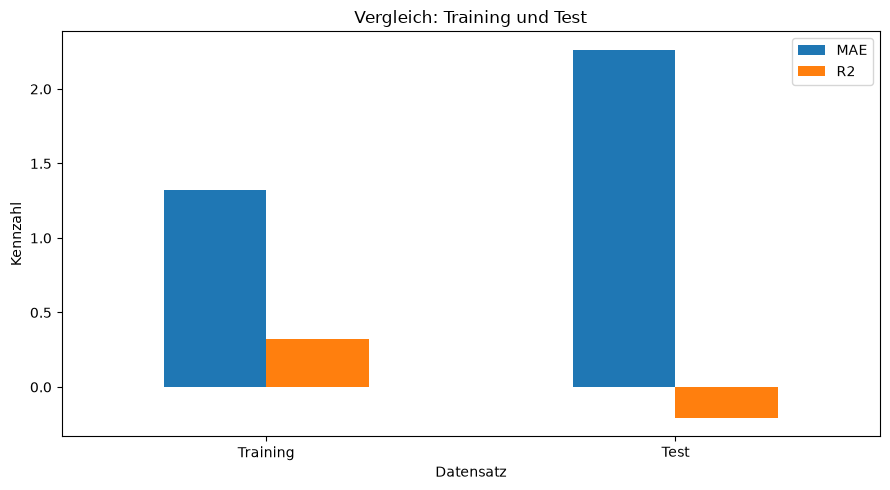

,Modell,MAE,R²
0,Baseline (nur pm25_lowcost),2.1627,-0.0046
1,Ausgewähltes Feature-Modell,2.2634,-0.2087


Test: absolute MAE-Verbesserung = -0.1007 (positiv ist besser)
Test: relative MAE-Verbesserung = -4.66 %
Test: absolute R²-Veränderung = -0.2041 (positiv ist besser)


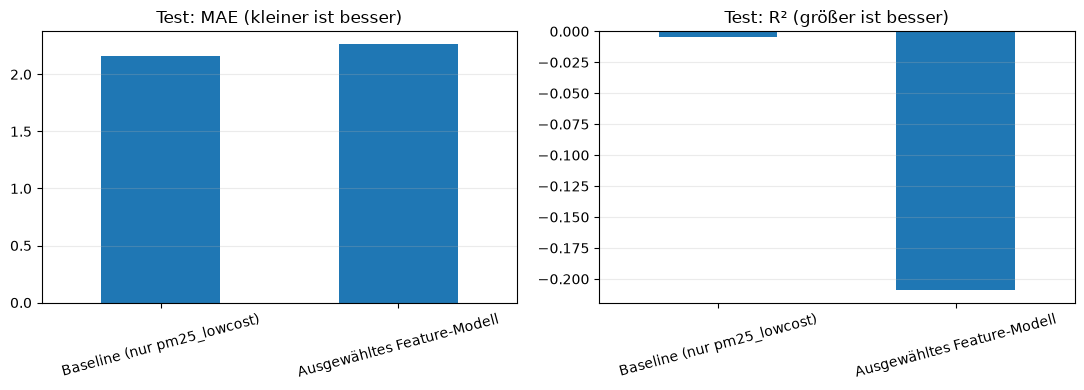

FAZIT: Auf dem offiziellen Test ist das Feature-Modell beim MAE schlechter als die Baseline.
Die Auswahl erfolgte ausschließlich auf Validierungsdaten.


In [15]:
# Auswahl nur mit der Validierung (Testdaten sind bis hier nicht verwendet worden)
best = results_df.loc[results_df["MAE"].idxmin()]
best_features = best["Features"]
print("Beste Feature-Kombination:", best_features)
print("Validierung MAE:", round(best["MAE"], 4), "R²:", round(best["R2"], 4))

# Endmodell: alle Trainingsdaten MIT gültigem Target für das Modelltraining
final_train = labeled.copy()
test = pd.read_csv(datenordner / "pm25_test.csv")
assert len(test) == 1464
assert "pm25_target" in test.columns

# Imputation ausschließlich anhand der Trainingsstatistik
train_medians = final_train[best_features].median()
X_final = final_train[best_features].fillna(train_medians)
X_test = test[best_features].fillna(train_medians)
final_reg = linear_model.LinearRegression()
final_reg.fit(X_final, final_train["pm25_target"])
test_predictions = final_reg.predict(X_test)

# Vergleich mit der ursprünglichen Baseline auf exakt denselben Testzeilen
base_features = ["pm25_lowcost"]
base_medians = final_train[base_features].median()
base_reg = linear_model.LinearRegression()
base_reg.fit(final_train[base_features].fillna(base_medians), final_train["pm25_target"])
baseline_predictions = base_reg.predict(test[base_features].fillna(base_medians))

# Fehlende Test-Labels nicht verändern oder Zeilen aus test entfernen.
# MAE/R² können mathematisch nur für vorhandene Referenzwerte berechnet werden.
valid_target = test["pm25_target"].notna()
observed_target = test.loc[valid_target, "pm25_target"]
from sklearn.metrics import r2_score

test_mae = mean_absolute_error(observed_target, test_predictions[valid_target.to_numpy()])
test_r2 = r2_score(observed_target, test_predictions[valid_target.to_numpy()])
base_mae_test = mean_absolute_error(observed_target, baseline_predictions[valid_target.to_numpy()])
base_r2_test = r2_score(observed_target, baseline_predictions[valid_target.to_numpy()])

print("Testzeilen insgesamt:", len(test))
print("Testzeilen mit vorhandenem Label:", valid_target.sum())
print("Testzeilen ohne Label:", (~valid_target).sum())
print("Offizieller Test – Baseline MAE / R²:", round(base_mae_test, 4), round(base_r2_test, 4))
print("Offizieller Test – Bestes Modell MAE / R²:", round(test_mae, 4), round(test_r2, 4))
print("MAE Verbesserung absolut:", round(base_mae_test-test_mae, 4))
print("MAE Verbesserung relativ (%):", round((base_mae_test-test_mae)/base_mae_test*100, 2))

# Unveränderte Testdaten plus Prognose: alle 1.464 Zeilen bleiben erhalten
predictions_output = test.copy()
predictions_output["pm25_prediction"] = test_predictions
predictions_output.to_csv("pm25_test_predictions.csv", index=False)
print("Testprognosen gespeichert: pm25_test_predictions.csv")

# Koeffizienten mal Standardabweichung (nur als Annäherung an Merkmals-Einfluss)
importance = pd.Series(final_reg.coef_ * X_final.std().values, index=best_features).sort_values()
importance.plot.barh(figsize=(9, 6), title="Regressionskoeffizienten × Trainings-Standardabweichung")
plt.xlabel("Einfluss auf Prognose je 1 Standardabweichung (mit Vorzeichen)")
plt.tight_layout()
plt.show()
print("Achtung: Korrelationen zwischen Features können Koeffizienten verzerren.")

# Vorhersagen für die Trainingsdaten mit dem besten Modell
train_predictions = final_reg.predict(X_final)

# MAE und R² für die Trainingsdaten berechnen
train_mae = mean_absolute_error(
    final_train["pm25_target"], train_predictions
)

train_r2 = r2_score(
    final_train["pm25_target"], train_predictions
)

# Ergebnisse von Training und Test vergleichen
vergleich = pd.DataFrame({
    "Datensatz": ["Training", "Test"],
    "MAE": [train_mae, test_mae],
    "R2": [train_r2, test_r2]
})

display(vergleich.round(4))

# Grafischer Vergleich der Ergebnisse
vergleich.plot(
    x="Datensatz",
    y=["MAE", "R2"],
    kind="bar",
    figsize=(9, 5),
    title="Vergleich: Training und Test"
)

plt.ylabel("Kennzahl")
plt.xticks(rotation=0)
plt.tight_layout()
plt.show()

# Direkte Gegenüberstellung auf exakt denselben auswertbaren Testzeilen
test_vergleich = pd.DataFrame({
    "Modell": ["Baseline (nur pm25_lowcost)", "Ausgewähltes Feature-Modell"],
    "MAE": [base_mae_test, test_mae],
    "R²": [base_r2_test, test_r2]
})
display(test_vergleich.round(4))

mae_delta = base_mae_test - test_mae
r2_delta = test_r2 - base_r2_test
print(f"Test: absolute MAE-Verbesserung = {mae_delta:+.4f} (positiv ist besser)")
print(f"Test: relative MAE-Verbesserung = {mae_delta/base_mae_test*100:+.2f} %")
print(f"Test: absolute R²-Veränderung = {r2_delta:+.4f} (positiv ist besser)")

fig, axes = plt.subplots(1, 2, figsize=(11, 4))
test_vergleich.plot(x="Modell", y="MAE", kind="bar", ax=axes[0], legend=False,
                     title="Test: MAE (kleiner ist besser)")
test_vergleich.plot(x="Modell", y="R²", kind="bar", ax=axes[1], legend=False,
                     title="Test: R² (größer ist besser)")
for ax in axes:
    ax.set_xlabel("")
    ax.tick_params(axis="x", rotation=15)
    ax.grid(axis="y", alpha=0.25)
plt.tight_layout()
plt.show()

# Interpretationshilfe zu den tatsächlich berechneten Ergebnissen
if test_mae > base_mae_test:
    print("FAZIT: Auf dem offiziellen Test ist das Feature-Modell beim MAE schlechter als die Baseline.")
elif test_mae < base_mae_test:
    print("FAZIT: Auf dem offiziellen Test verbessert das Feature-Modell den MAE gegenüber der Baseline.")
else:
    print("FAZIT: Auf dem offiziellen Test haben beide Modelle denselben MAE.")
print("Die Auswahl erfolgte ausschließlich auf Validierungsdaten.")

### Streudiagramme: tatsächliche gegen vorhergesagte PM2.5-Werte

Die folgenden **vier Streudiagramme** vergleichen die Baseline (`pm25_lowcost`) mit der auf der **Validierung ausgewählten Feature-Kombination** – jeweils auf Validierungs- und offiziellen Testdaten. Jeder Punkt ist eine Messung: auf der x-Achse steht der tatsächliche PM2.5-Wert, auf der y-Achse die Vorhersage. Die gestrichelte Diagonale (`y = x`) kennzeichnet perfekte Vorhersagen. Je näher die Punkte an der Linie liegen, desto kleiner sind die Vorhersagefehler.

Für die **Validierung** werden die Modelle nur mit `train` trainiert. Für den **offiziellen Test** werden die bereits erstellten Modelle verwendet, die nach der Feature-Auswahl auf allen gelabelten Trainingsdaten neu trainiert wurden. Die Testdaten werden **nicht** zur Feature-Auswahl genutzt. Alle Testzeilen behalten ihre Vorhersage; nur für Zeilen mit vorhandenem Referenzwert ist ein Punkt bzw. eine Berechnung von MAE/R² möglich.


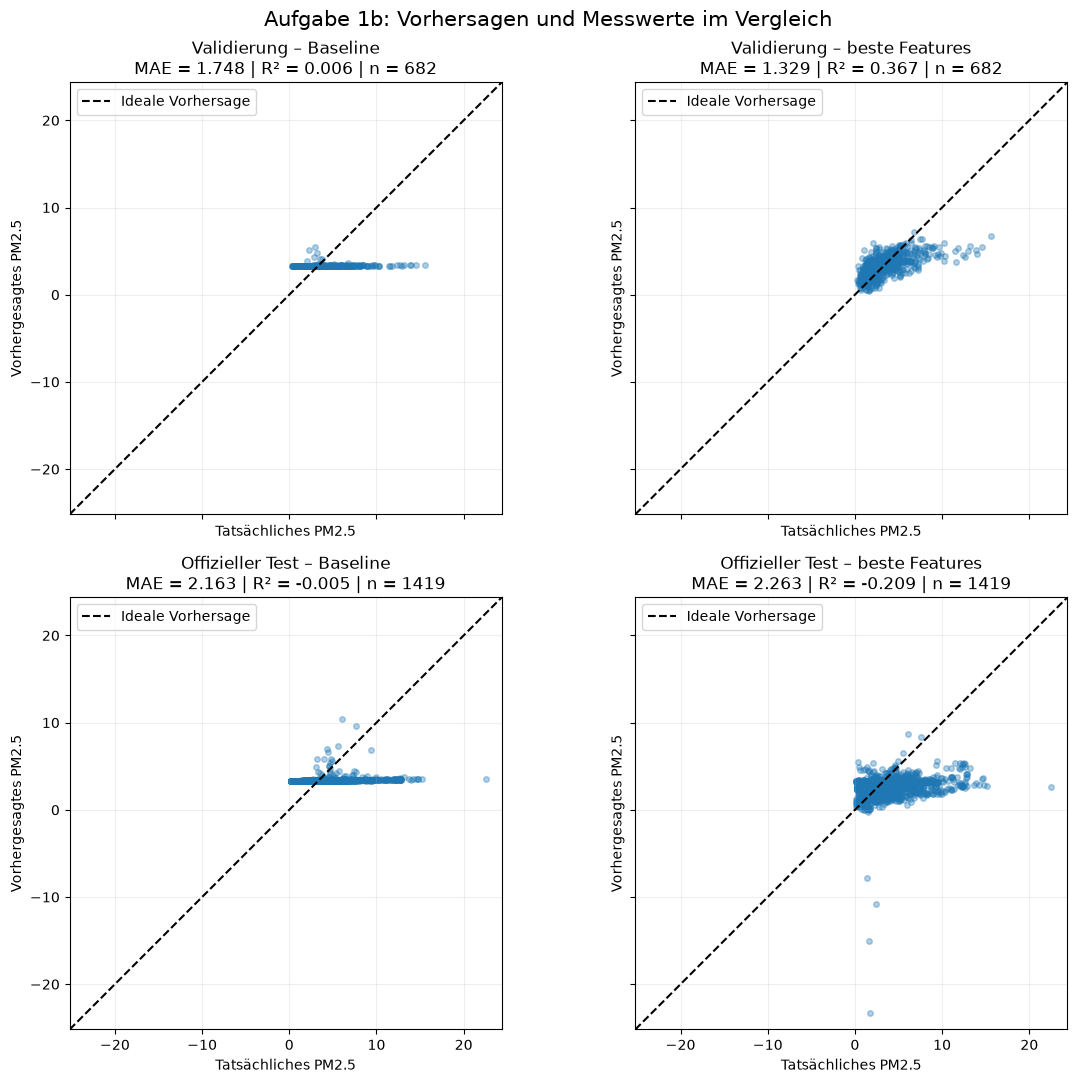

Offizieller Test: Vorhersagen für 1464 von 1464 Zeilen vorhanden; 1419 Zeilen mit auswertbarem Zielwert.


In [14]:
# 1b – Streudiagramme: Ist-Wert vs. Vorhersage (Baseline und ausgewähltes Modell)
# Validierungsmodelle: nur auf train fitten, damit keine Validierungslabels in das Training gelangen.
val_base_model, _, _ = evaluate(["pm25_lowcost"], train, valid)
val_best_model, _, _ = evaluate(best_features, train, valid)
_, X_val_base = prepare(train, valid, ["pm25_lowcost"])
_, X_val_best = prepare(train, valid, best_features)
val_base_pred = val_base_model.predict(X_val_base)
val_best_pred = val_best_model.predict(X_val_best)

# Für den Test werden die zuvor auf final_train trainierten Modelle verwendet.
# Testzeilen mit fehlendem Zielwert werden NICHT gelöscht: Es gibt nur keinen Ist-Wert zum Plotten.
test_mask = valid_target.to_numpy()
y_val = valid["pm25_target"].to_numpy()
y_test = test.loc[valid_target, "pm25_target"].to_numpy()

plots = [
    ("Validierung – Baseline", y_val, val_base_pred),
    ("Validierung – beste Features", y_val, val_best_pred),
    ("Offizieller Test – Baseline", y_test, baseline_predictions[test_mask]),
    ("Offizieller Test – beste Features", y_test, test_predictions[test_mask]),
]

# Gemeinsame Achsen erleichtern einen fairen visuellen Vergleich.
all_values = np.concatenate([np.asarray(y) for _, truth, prediction in plots
                             for y in (truth, prediction)])
axis_min, axis_max = float(np.min(all_values)), float(np.max(all_values))
padding = max((axis_max - axis_min) * 0.04, 0.1)
limits = (axis_min - padding, axis_max + padding)

fig, axes = plt.subplots(2, 2, figsize=(12, 11), sharex=True, sharey=True)
for ax, (title, truth, prediction) in zip(axes.flat, plots):
    ax.scatter(truth, prediction, alpha=0.35, s=16)
    ax.plot(limits, limits, "--", color="black", lw=1.5, label="Ideale Vorhersage")
    ax.set_xlim(limits)
    ax.set_ylim(limits)
    ax.set_aspect("equal", adjustable="box")
    mae_plot = mean_absolute_error(truth, prediction)
    r2_plot = r2_score(truth, prediction)
    ax.set_title(f"{title}\nMAE = {mae_plot:.3f} | R² = {r2_plot:.3f} | n = {len(truth)}")
    ax.set_xlabel("Tatsächliches PM2.5")
    ax.set_ylabel("Vorhergesagtes PM2.5")
    ax.grid(alpha=0.2)
    ax.legend(loc="upper left")
plt.suptitle("Aufgabe 1b: Vorhersagen und Messwerte im Vergleich", fontsize=15)
plt.tight_layout()
plt.show()

print(f"Offizieller Test: Vorhersagen für {len(test)} von {len(test)} Zeilen vorhanden; "
      f"{len(y_test)} Zeilen mit auswertbarem Zielwert.")


### Interpretation und Learnings zu Aufgabe 1b

Die Ergebnisse der Modellwahl und der Testbewertung wurden mit einer **80/20-Aufteilung** (Training/Validierung) neu berechnet. Sie sind in den ausgeführten Ergebniszellen unmittelbar darüber dokumentiert. Die folgenden Punkte sind bei der Interpretation wichtig:

1. **Baseline:** Die lineare Regression startet ausschließlich mit `pm25_lowcost`. Ihr Validierungs-MAE dient als Vergleichsmaßstab.
2. **Schrittweise Feature-Auswahl:** Greedy Forward Selection fügt jeweils das Merkmal mit dem niedrigsten Validierungs-MAE hinzu. Die Kombination mit dem insgesamt niedrigsten MAE wird danach gewählt; zusätzliche Merkmale können auch verschlechtern.
3. **Unabhängiger Test:** Erst nach der Auswahl werden die finalen Modelle auf allen geeigneten Trainingszeilen neu trainiert und auf `pm25_test.csv` getestet. Die offiziellen Testdaten werden nicht für die Auswahl verwendet.
4. **Datenqualität:** Fehlende Eingabewerte werden mit dem jeweiligen Median der Trainingsdaten ersetzt. Testzeilen werden nicht entfernt; Test-Labels werden nicht geändert.
5. **Interpretation:** Vergleiche jeweils MAE und R² auf der Validierung und auf dem Test. Ein besserer Validierungs-MAE garantiert keine bessere Testleistung. Regressionskoeffizienten sind kein Kausalitätsnachweis.

Die konkreten **neu berechneten Zahlen** stehen in der Ergebnistabelle und den Diagrammen; ältere Ergebnisse der vorherigen 60/20/20-Aufteilung sind nicht mehr gültig.